In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from maze_env import MazeEnv

In [2]:
print("Repertoire :", os.getcwd())
print("Labyrinthe etat initial :", MazeEnv().reset())

Repertoire : C:\Users\user\PycharmProjects\Tps_AI\TP4_AI
Labyrinthe etat initial : 0


In [3]:
import numpy as np
n_states = 25
n_actions = 4
Q = np.zeros((n_states, n_actions))
print('Dimensions de Q :', Q.shape)

Dimensions de Q : (25, 4)


In [4]:
def choisir_action(state, Q, epsilon):
  if np.random.random() < epsilon:
    return np.random.randint(Q.shape[1])
  return int(np.argmax(Q[state]))

print('Action gloutonne depuis 0 :', choisir_action(0, Q, 0))

Action gloutonne depuis 0 : 0


In [5]:
def update_q(Q, state, action, reward, next_state,
 terminated, alpha=0.1, gamma=0.95):
 future = 0.0 if terminated else np.max(Q[next_state])
 target = reward + gamma * future
 Q[state, action] += alpha * (target - Q[state, action])
 return Q

 # Test independant : la valeur Q augmente ou diminue
Q_test = np.zeros((25, 4))
update_q(Q_test, 0, 0, -10, 0, False)
print('Nouvelle valeur :', Q_test[0, 0])

Nouvelle valeur : -1.0


In [6]:
def train_maze(epsilon_initial=1.0, seed=42, episodes=1000):
 np.random.seed(seed)
 env = MazeEnv()
 table = np.zeros((25, 4))
 epsilon = epsilon_initial
 history = []

 for episode in range(episodes):
  state = env.reset()
  total = 0.0

  for _ in range(100):
   action = choisir_action(state, table, epsilon)
   s_next, reward, terminated = env.step(action)
   update_q(table, state, action, reward, s_next,
   terminated, alpha=0.1, gamma=0.95)
   total += reward
   state = s_next
   if terminated:
    break
   history.append(total)
   epsilon = max(0.01, epsilon * 0.995) if epsilon_initial > 0 else 0.0

 return table, history

Q_explore, rewards_explore = train_maze(epsilon_initial=1.0)
print('Q :', Q_explore.shape, 'Episodes :', len(rewards_explore))

Q : (25, 4) Episodes : 7470


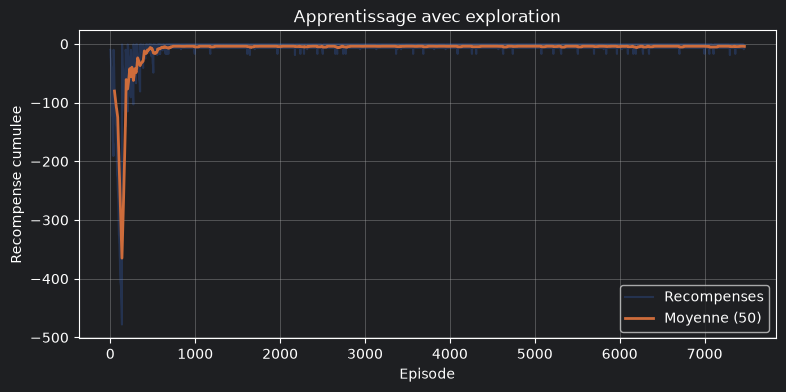

In [7]:
def plot_learning(history, title):
  window = 50
  avg = np.convolve(history, np.ones(window)/window, mode='valid')
  plt.figure(figsize=(9, 4))
  plt.plot(history, alpha=0.25, label='Recompenses')
  plt.plot(range(window-1, len(history)), avg, linewidth=2, label='Moyenne (50)')
  plt.xlabel('Episode')
  plt.ylabel('Recompense cumulee')
  plt.title(title)
  plt.legend()
  plt.grid(True)
  plt.show()

plot_learning(rewards_explore, 'Apprentissage avec exploration')

In [8]:
def tester_maze(table, max_steps=100):
 env = MazeEnv()
 state = env.reset()
 path = [state]
 total = 0.0
 reached = False

 for _ in range(max_steps):
   action = int(np.argmax(table[state]))
   state, reward, terminated = env.step(action)
   path.append(state)
   total += reward
   if terminated:
     reached = True
     break
 return reached, path, total

success, path, reward = tester_maze(Q_explore)
print('Arrivee atteinte :', success)
print('Etats parcourus :', path)
print('Nombre de deplacements :', len(path) - 1)
print('Recompense :', reward)

Arrivee atteinte : True
Etats parcourus : [0, 1, 2, 7, 12, 13, 14, 19, 24]
Nombre de deplacements : 8
Recompense : 93.0


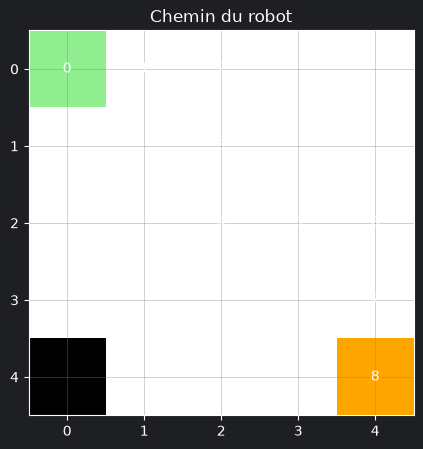

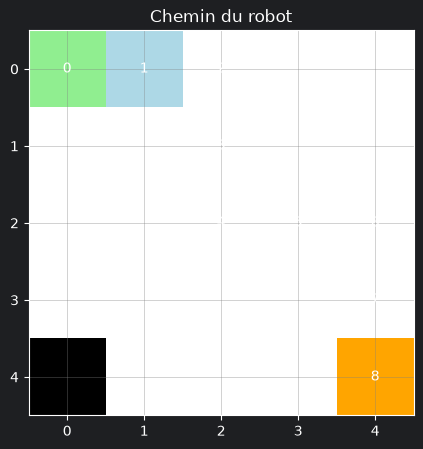

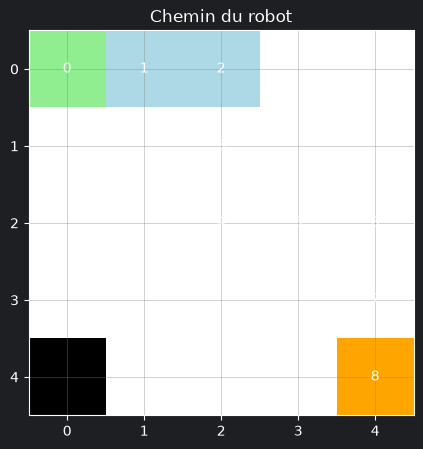

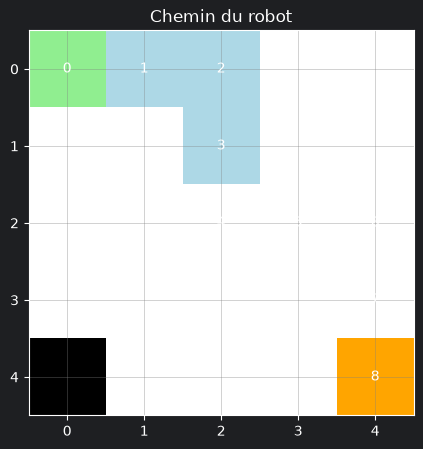

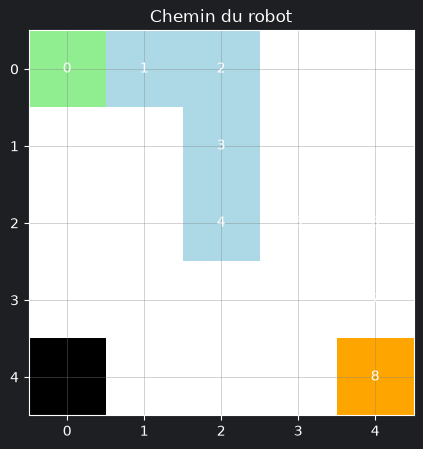

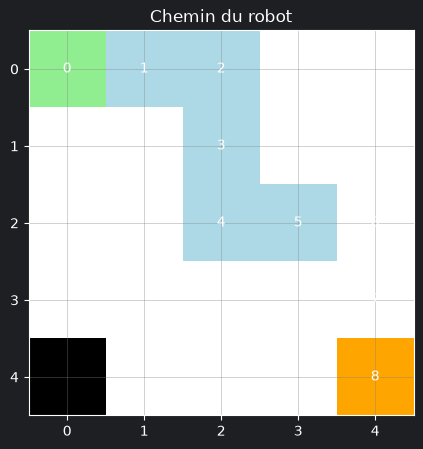

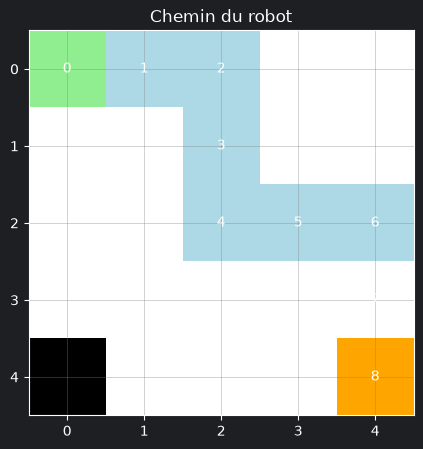

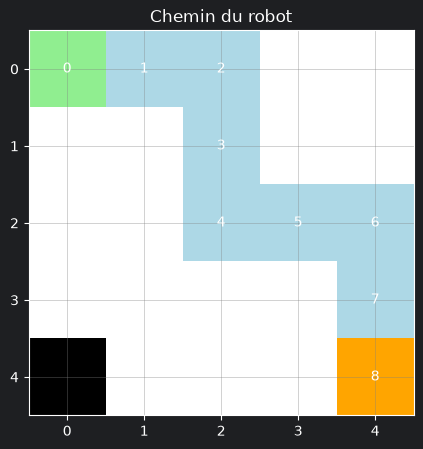

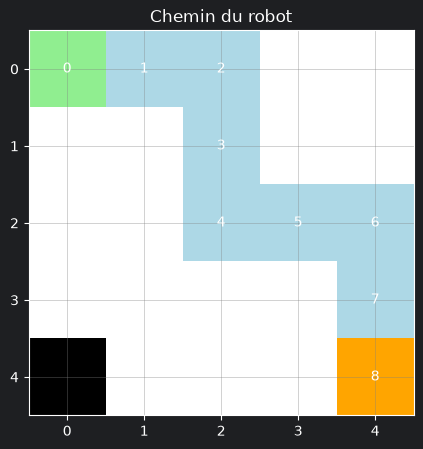

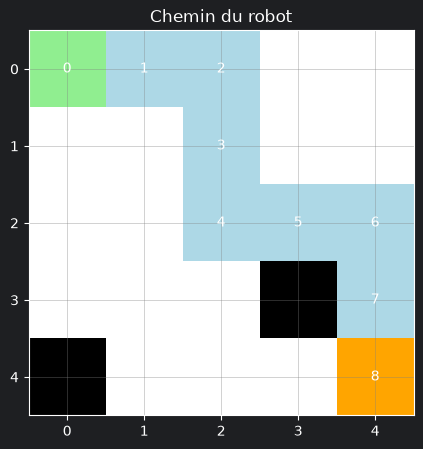

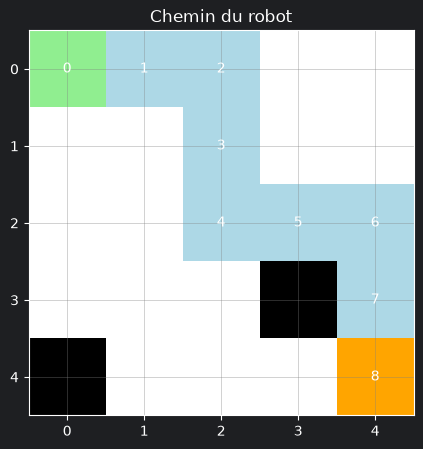

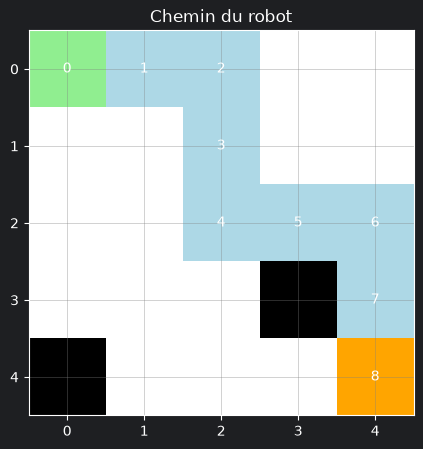

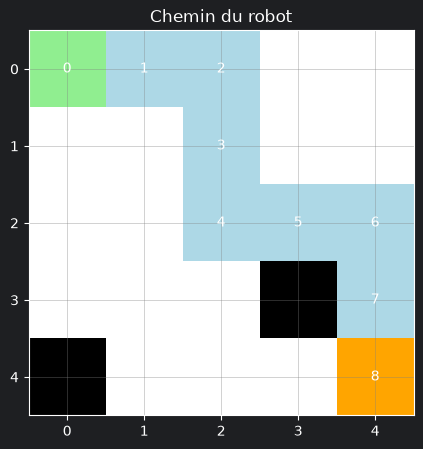

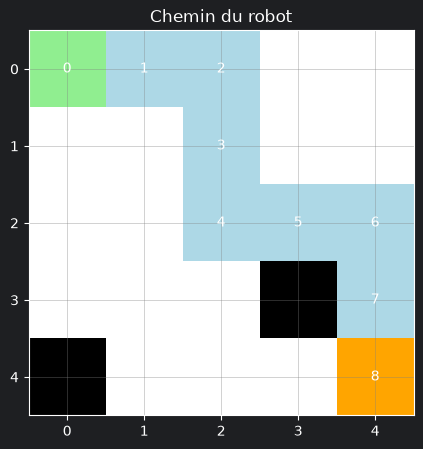

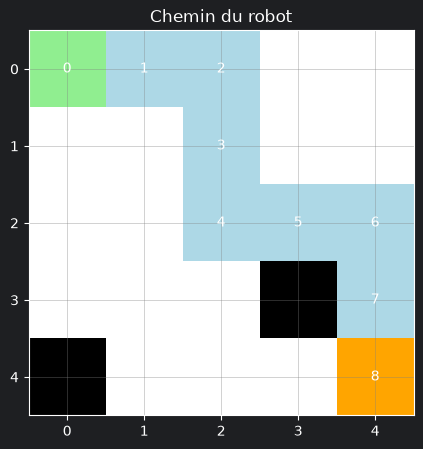

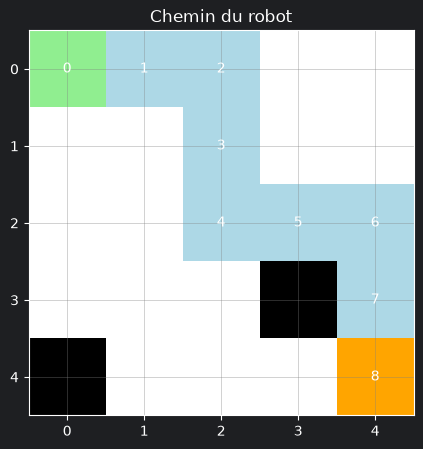

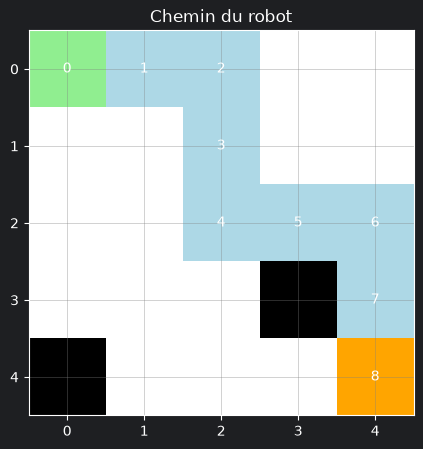

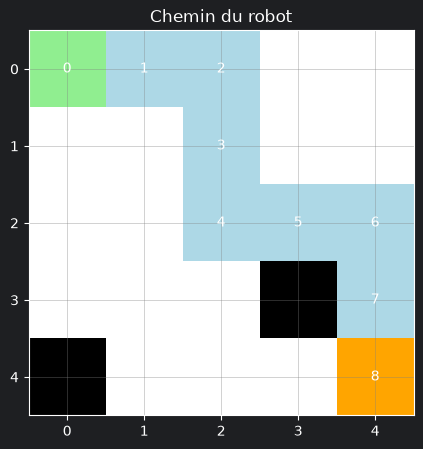

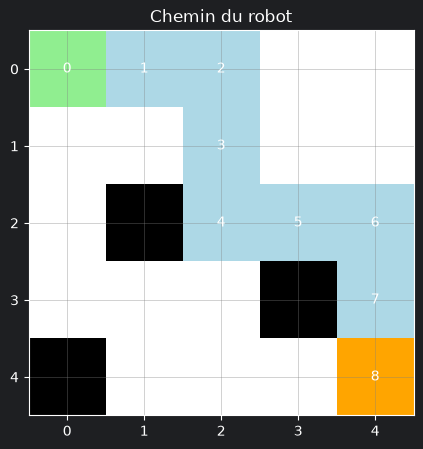

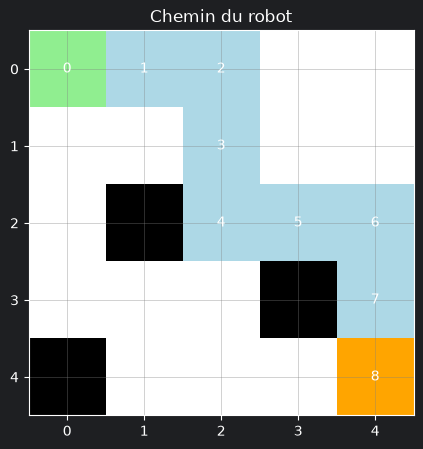

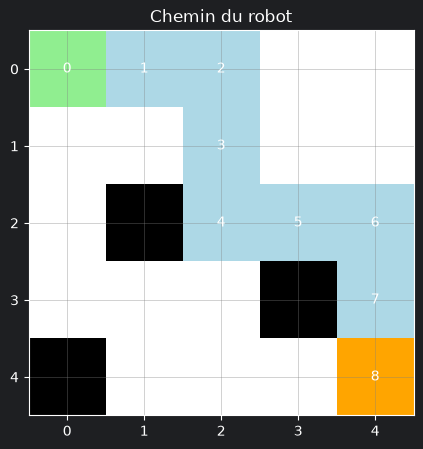

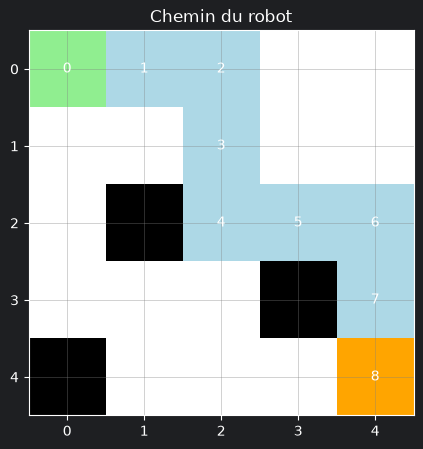

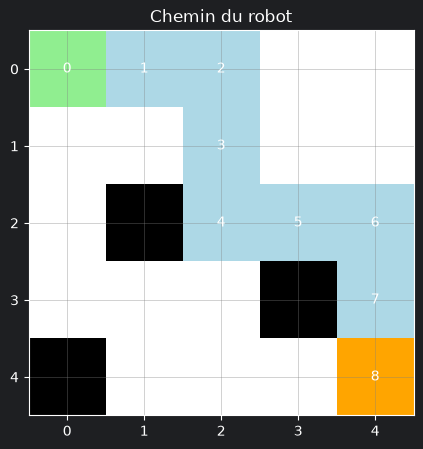

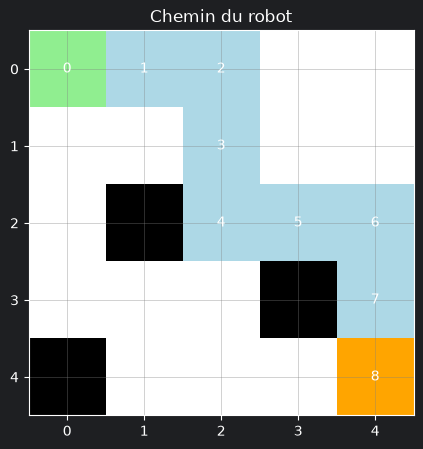

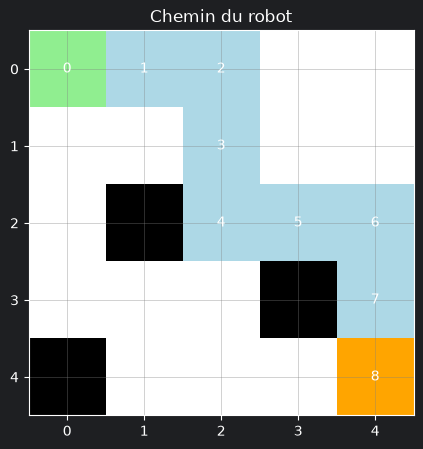

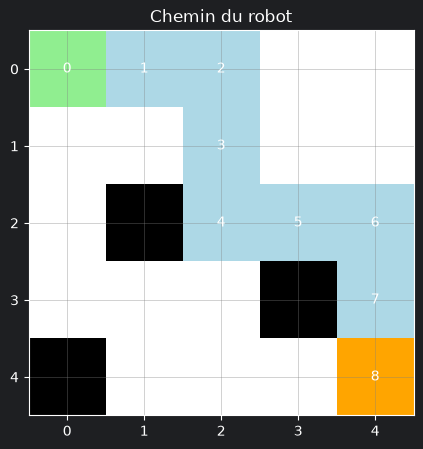

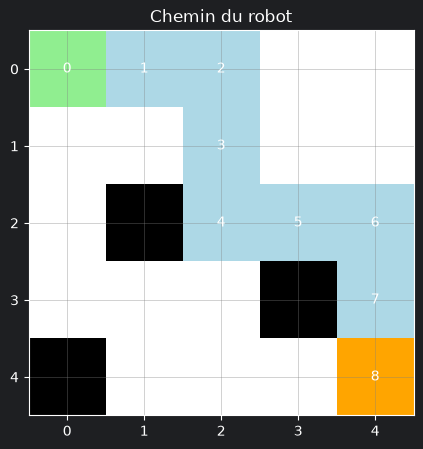

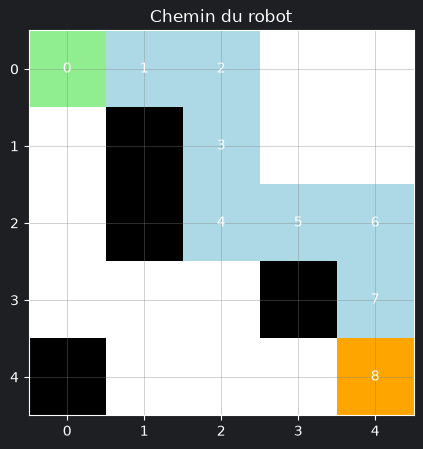

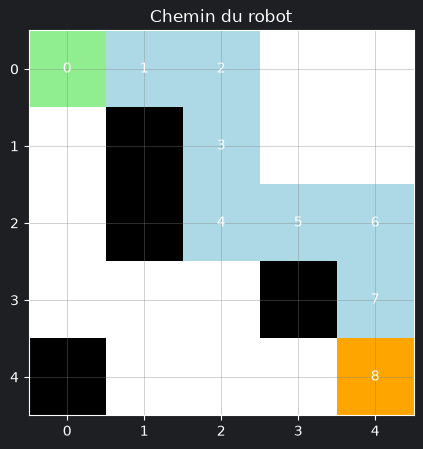

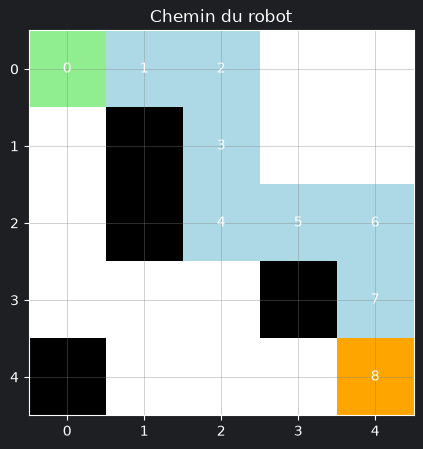

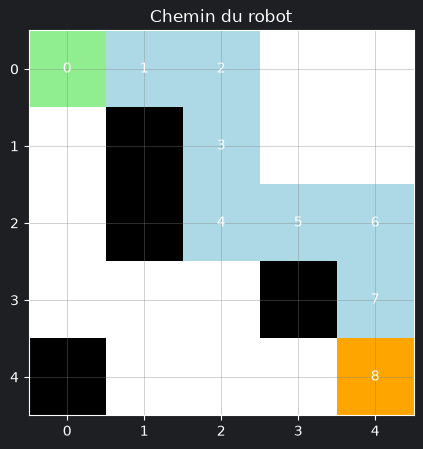

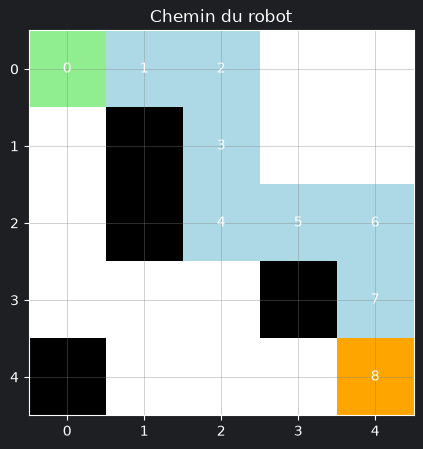

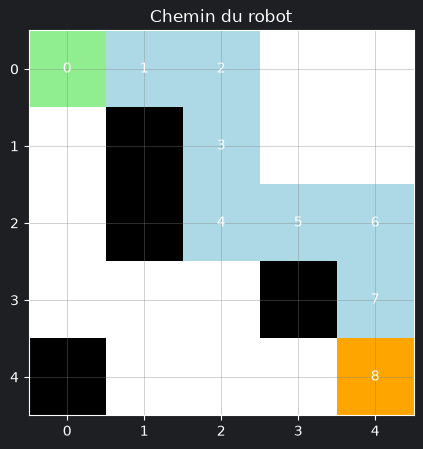

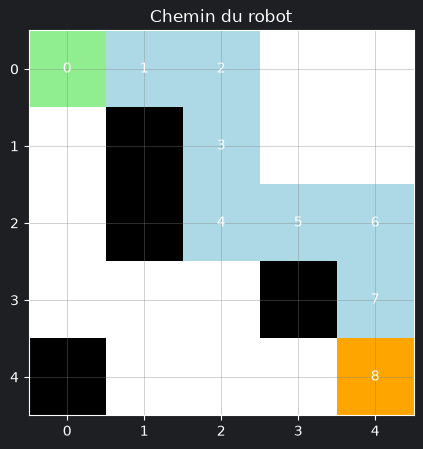

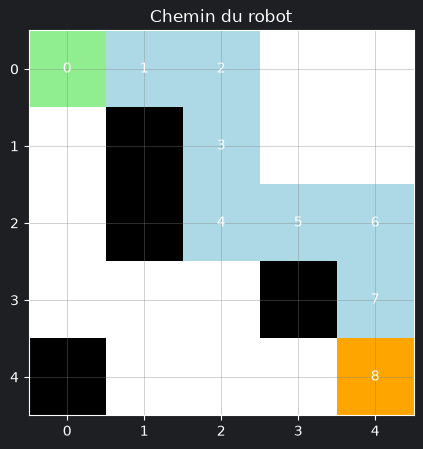

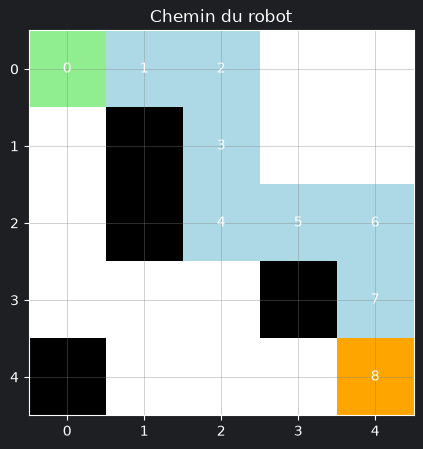

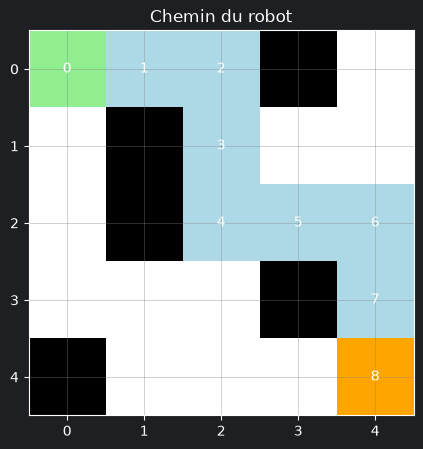

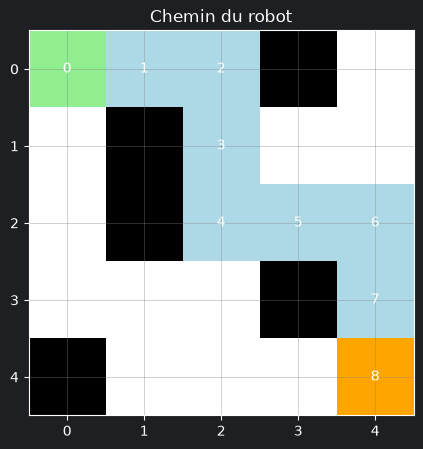

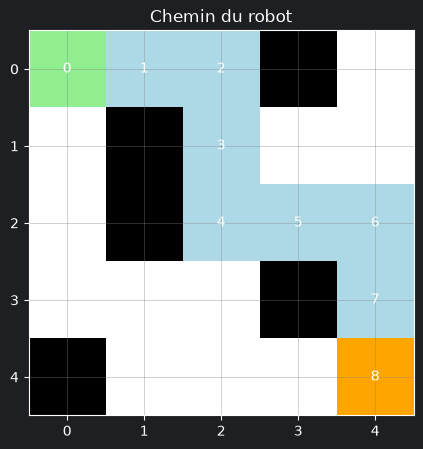

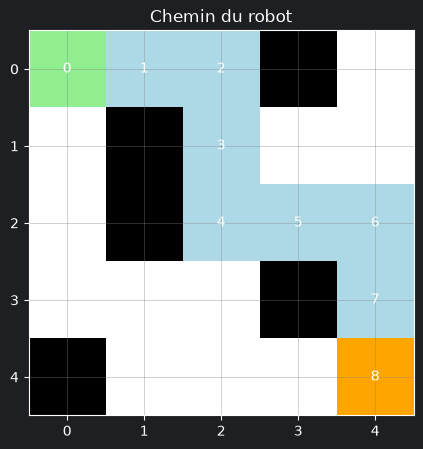

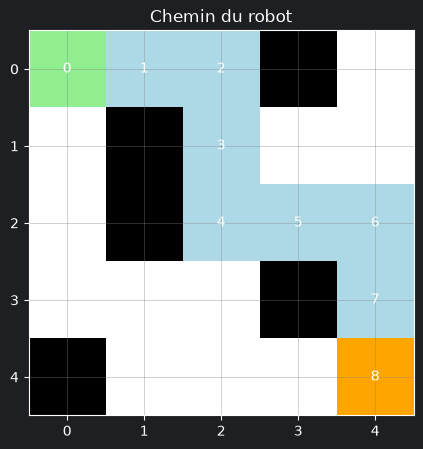

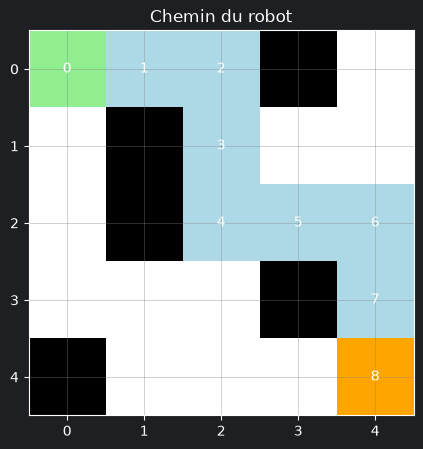

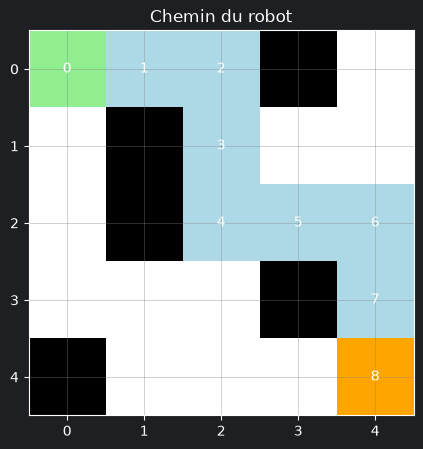

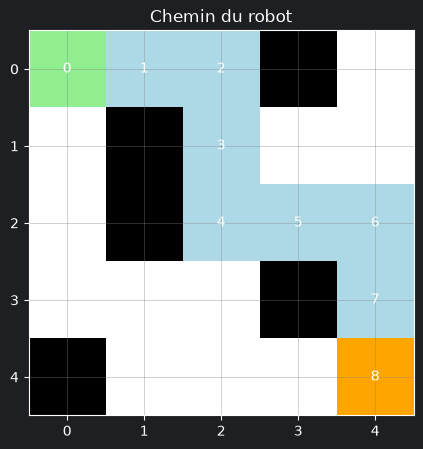

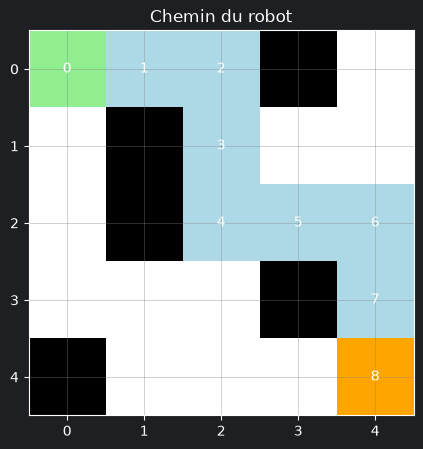

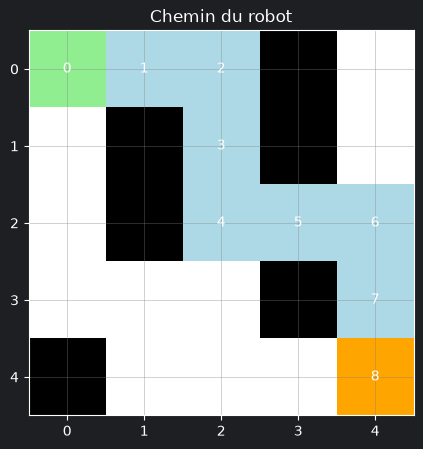

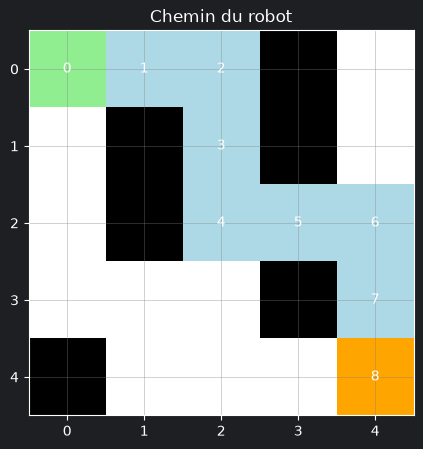

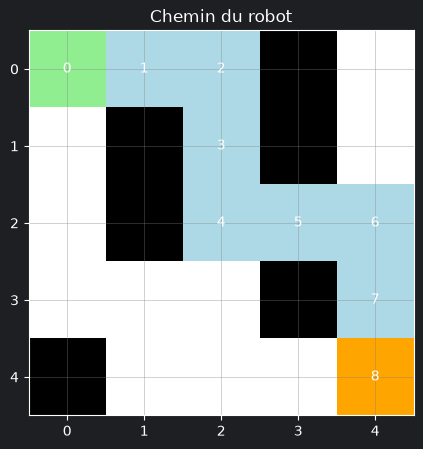

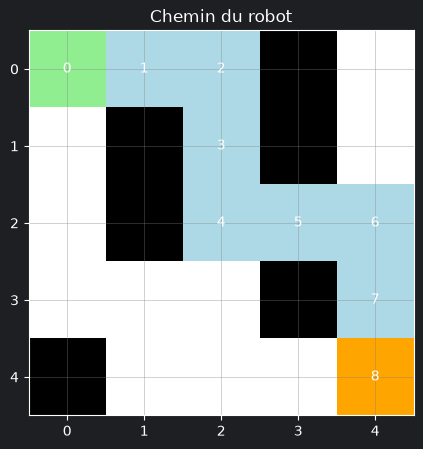

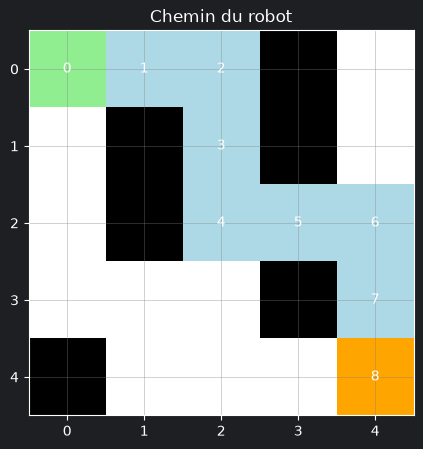

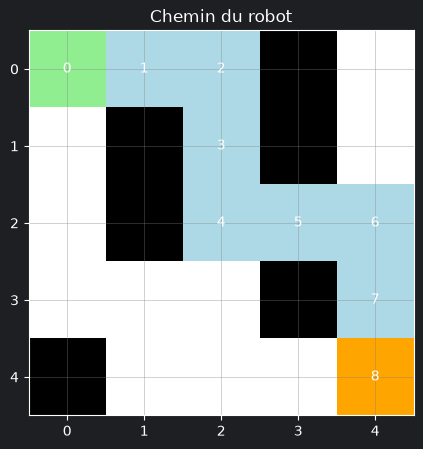

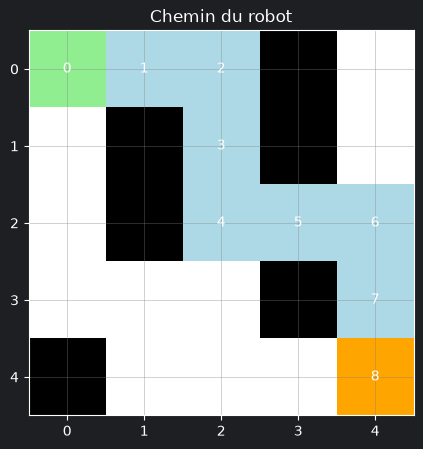

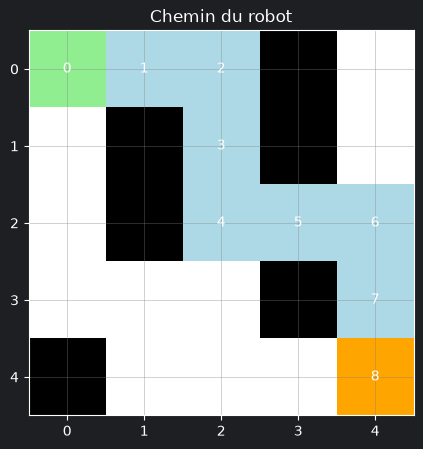

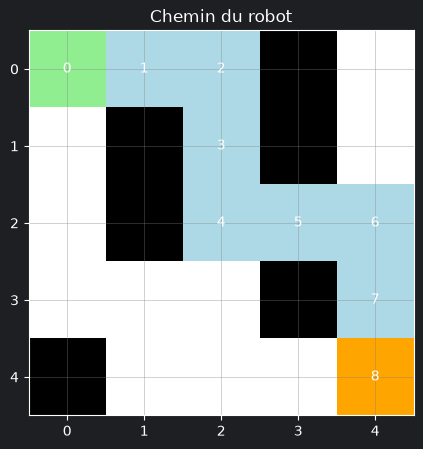

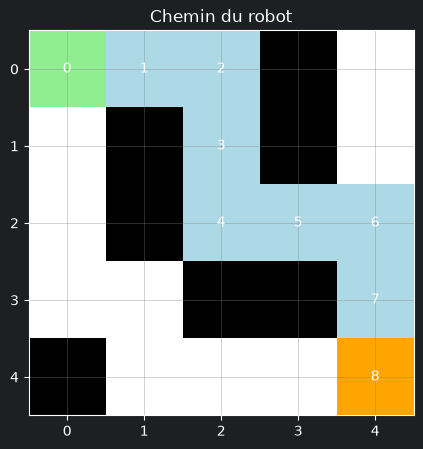

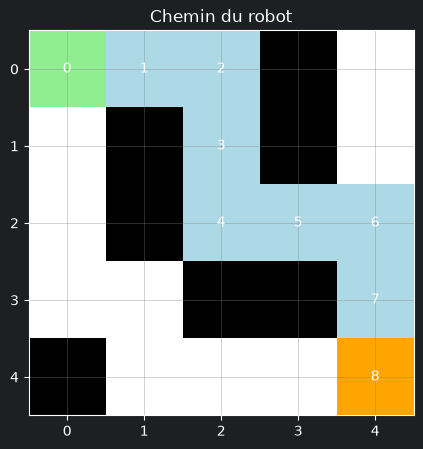

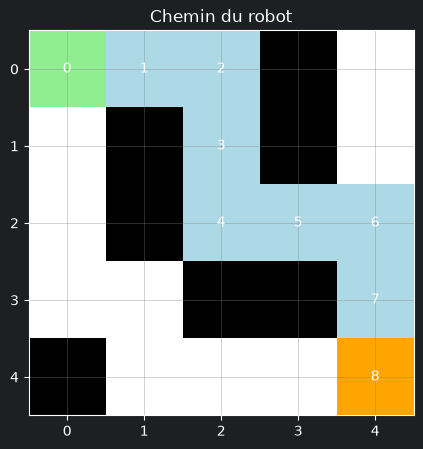

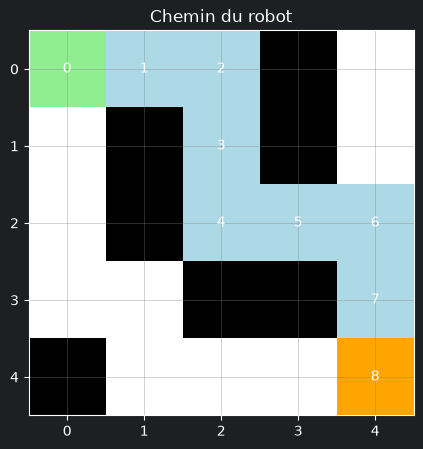

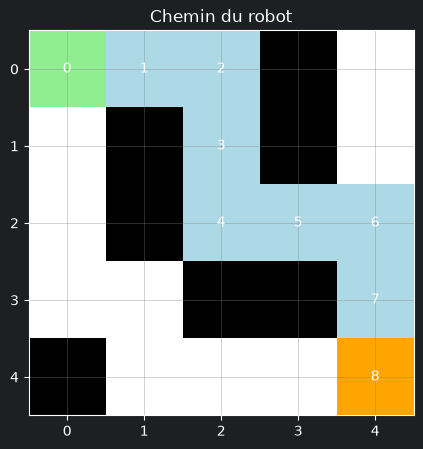

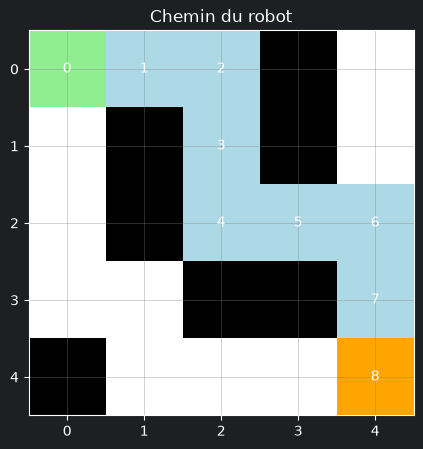

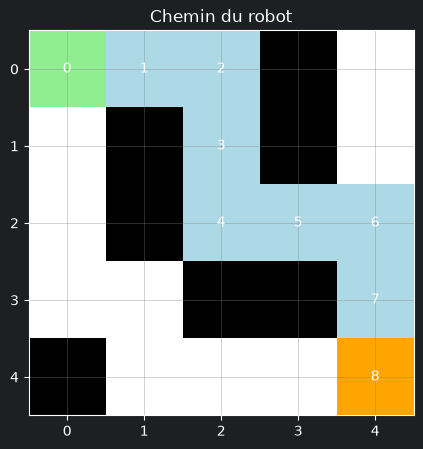

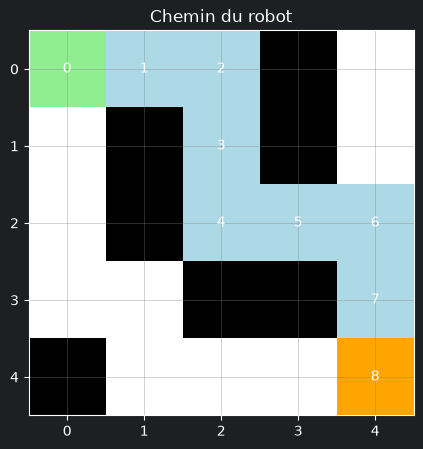

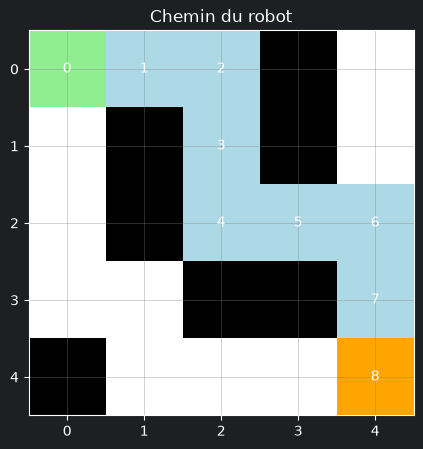

In [9]:
def plot_maze_path(path, title='Chemin du robot'):
 obstacles = {(0,3), (1,1), (1,3), (2,1), (3,2), (3,3), (4,0)}
 grid = np.zeros((5, 5), dtype=int)
 for r, c in obstacles:
     grid[r,c] = 1
     for s in path:
        r, c = divmod(s, 5)

        if (r,c) not in obstacles:
            grid[r,c] = 2
            grid[0,0] = 3; grid[4,4] = 4
            cmap = ListedColormap(['white','black','lightblue', 'lightgreen','orange'])
            plt.figure(figsize=(5,5))
            plt.imshow(grid, cmap=cmap, vmin=0, vmax=4)
            plt.xticks(range(5)); plt.yticks(range(5))
            plt.grid(color='gray')

            for i,s in enumerate(path):
                r,c = divmod(s, 5)
                plt.text(c, r, str(i), ha='center', va='center')
            plt.title(title)
            plt.show()

plot_maze_path(path)

Avec exploration reussite= True actions= 8 recompense= 93.0
Sans exploration reussite= True actions= 8 recompense= 93.0


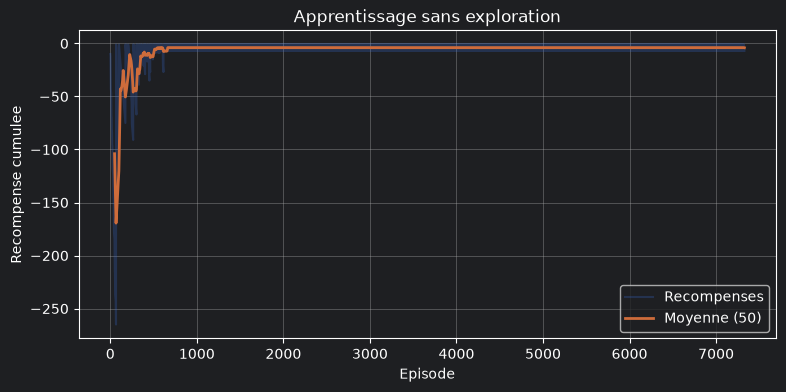

In [10]:
Q_sans, rewards_sans = train_maze(epsilon_initial=0.0)

resultats = {
'Avec exploration': tester_maze(Q_explore),
'Sans exploration': tester_maze(Q_sans)
}

for nom, (ok, chemin, total) in resultats.items():
    print(nom, 'reussite=', ok,'actions=', len(chemin)-1,'recompense=', total)

plot_learning(rewards_sans, 'Apprentissage sans exploration')